# np.nn demo

A small neural network library written from scratch with NumPy: layers, losses, optimizers and a `Sequential` model with mini-batch training. This notebook trains it on moons, digits and the full MNIST.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

from nn import Sequential, Linear, ReLU, Dropout, Adam, NN, set_seed
from nn.utils import load_moons, load_digits, load_mnist, train_test_split
from nn.viz import (plot_history, plot_decision_boundary, DecisionBoundaryRecorder,
                    animate_decision_boundary, confusion_matrix, plot_confusion_matrix)

os.makedirs("assets", exist_ok=True)
os.makedirs("results", exist_ok=True)
set_seed(0)
summary = {}

## 1. Moons

Two interleaved half circles. A `DecisionBoundaryRecorder` callback records the decision boundary after every epoch to make a GIF.

In [2]:
X, y = load_moons(1000, noise=0.1, seed=0)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, seed=0)

model = Sequential([Linear(2, 16), ReLU(), Linear(16, 16), ReLU(), Linear(16, 2)])
rec = DecisionBoundaryRecorder(Xtr, every=1, resolution=100)
hist = model.fit(Xtr, ytr, epochs=60, batch_size=32, optimizer=Adam(lr=1e-2),
                 validation_data=(Xte, yte), callbacks=[rec], verbose=False)
_, acc = model.evaluate(Xte, yte)
summary["Moons"] = acc
print(f"Test accuracy: {acc * 100:.2f}%")

Test accuracy: 100.00%


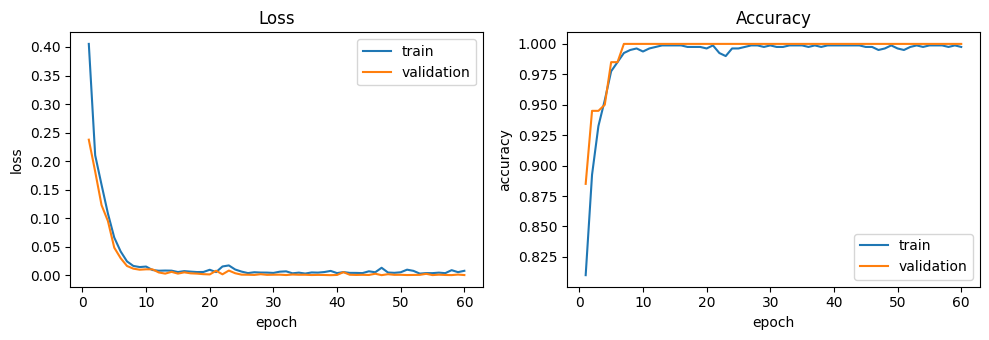

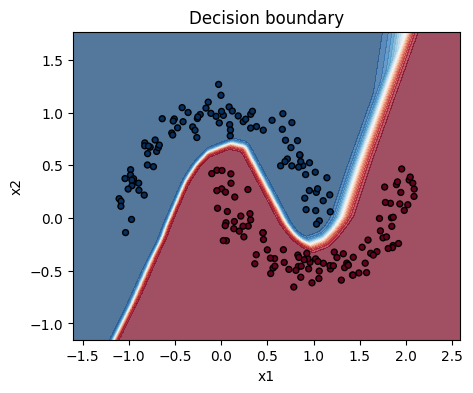

In [3]:
plot_history(hist, path="assets/moons_history.png")
plot_decision_boundary(model, Xte, yte, path="assets/moons_boundary.png")
animate_decision_boundary(rec, Xtr, ytr, "assets/moons_boundary.gif", fps=8)
plt.show()

## 2. The old API still works

`NN(layers=[...])` with data shaped `(N, features, 1)` and `train(X, Y, epochs, lr)`.

In [4]:
Xl = Xtr.reshape(-1, 2, 1)
Yl = np.eye(2)[ytr].reshape(-1, 2, 1)
old = NN(layers=[2, 16, 2], function='relu')
old.train(Xl, Yl, epochs=20, lr=0.01, verbose=False)
old.test(Xte.reshape(-1, 2, 1), np.eye(2)[yte].reshape(-1, 2, 1))

Test accuracy:  98.500%


0.985

## 3. Digits (8x8)

Test accuracy: 98.33%


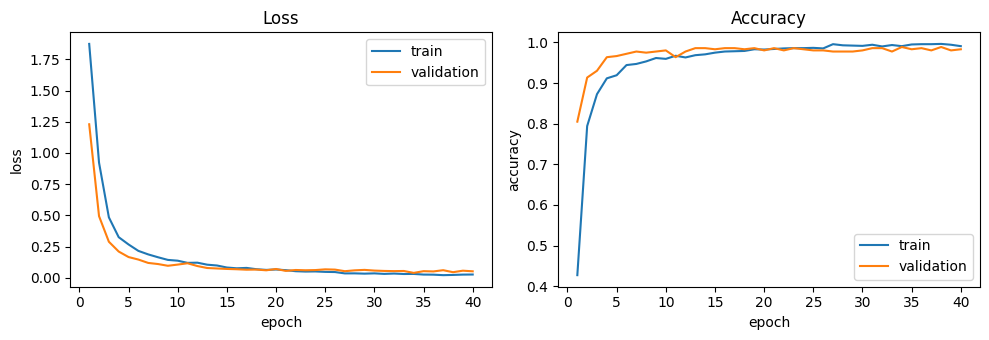

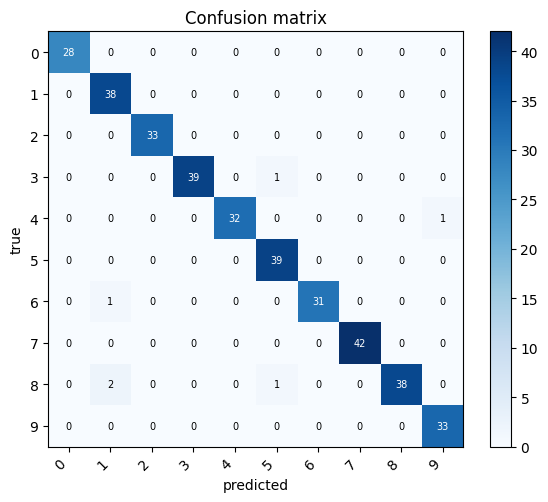

In [5]:
X, y = load_digits()
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, seed=0)

model = Sequential([Linear(64, 128), ReLU(), Dropout(0.2), Linear(128, 64), ReLU(), Linear(64, 10)])
hist = model.fit(Xtr, ytr, epochs=40, batch_size=32, optimizer=Adam(lr=1e-3),
                 validation_data=(Xte, yte), verbose=False)
_, acc = model.evaluate(Xte, yte)
summary["Digits 8x8"] = acc
print(f"Test accuracy: {acc * 100:.2f}%")
plot_history(hist, path="assets/digits_history.png")
cm = confusion_matrix(yte, model.predict(Xte), 10)
plot_confusion_matrix(cm, path="assets/digits_confusion.png")
plt.show()

## 4. MNIST (60k train / 10k test)

The first call downloads the dataset from OpenML and caches it in `~/.cache/npdl`.

In [6]:
(Xtr, ytr), (Xte, yte) = load_mnist()
set_seed(0)
model = Sequential([Linear(784, 256), ReLU(), Dropout(0.2), Linear(256, 128), ReLU(), Linear(128, 10)])
hist = model.fit(Xtr, ytr, epochs=10, batch_size=64, optimizer=Adam(lr=1e-3),
                 validation_data=(Xte, yte), verbose=True)
_, acc = model.evaluate(Xte, yte)
summary["MNIST"] = acc
print(f"\nMNIST test accuracy: {acc * 100:.2f}%")

Epoch 1/10 - loss: 0.2581 - accuracy: 92.320% - val_loss: 0.1097 - val_accuracy: 96.590%


Epoch 2/10 - loss: 0.1112 - accuracy: 96.560% - val_loss: 0.0860 - val_accuracy: 97.390%


Epoch 3/10 - loss: 0.0831 - accuracy: 97.403% - val_loss: 0.0761 - val_accuracy: 97.540%


Epoch 4/10 - loss: 0.0661 - accuracy: 97.900% - val_loss: 0.0699 - val_accuracy: 97.840%


Epoch 5/10 - loss: 0.0552 - accuracy: 98.193% - val_loss: 0.0660 - val_accuracy: 98.080%


Epoch 6/10 - loss: 0.0490 - accuracy: 98.382% - val_loss: 0.0635 - val_accuracy: 98.200%


Epoch 7/10 - loss: 0.0408 - accuracy: 98.657% - val_loss: 0.0699 - val_accuracy: 98.020%


Epoch 8/10 - loss: 0.0365 - accuracy: 98.710% - val_loss: 0.0723 - val_accuracy: 97.980%


Epoch 9/10 - loss: 0.0333 - accuracy: 98.852% - val_loss: 0.0729 - val_accuracy: 98.230%


Epoch 10/10 - loss: 0.0309 - accuracy: 98.952% - val_loss: 0.0604 - val_accuracy: 98.400%

MNIST test accuracy: 98.40%


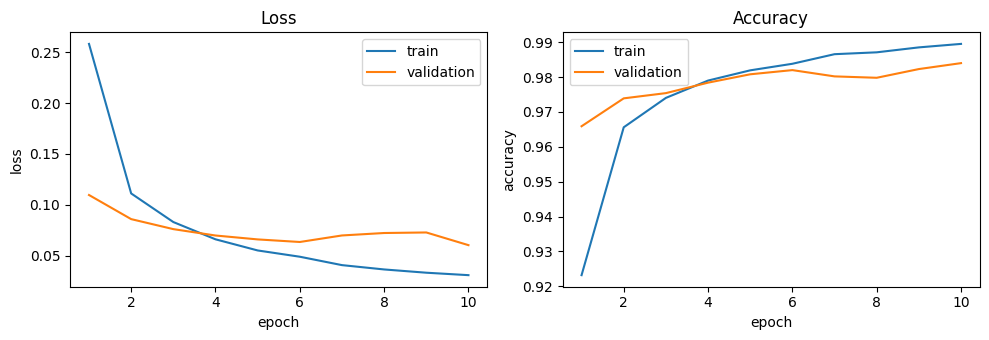

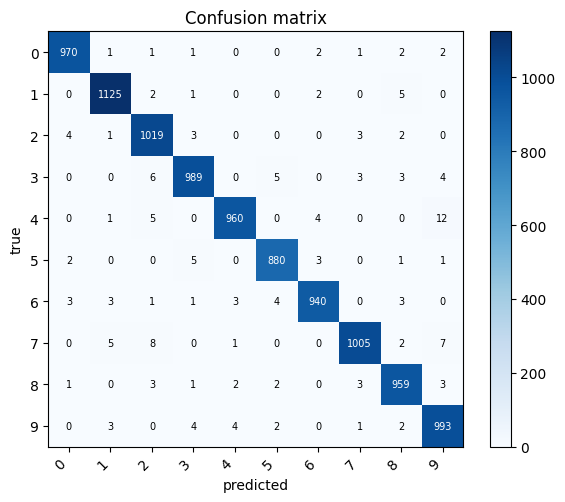

In [7]:
plot_history(hist, path="assets/mnist_history.png")
cm = confusion_matrix(yte, model.predict(Xte), 10)
plot_confusion_matrix(cm, path="assets/mnist_confusion.png")
plt.show()

In [8]:
model.save("results/mnist_mlp.npz")
clone = Sequential([Linear(784, 256), ReLU(), Dropout(0.2), Linear(256, 128), ReLU(), Linear(128, 10)])
clone.load("results/mnist_mlp.npz")
_, acc2 = clone.evaluate(Xte, yte)
assert abs(acc - acc2) < 1e-9, "load() must reproduce the accuracy"
print(f"Reloaded model accuracy: {acc2 * 100:.2f}%")

Reloaded model accuracy: 98.40%


## 5. Summary

In [9]:
print("| Dataset | Test accuracy |\n|---|---|")
for k, v in summary.items():
    print(f"| {k} | {v * 100:.2f}% |")

| Dataset | Test accuracy |
|---|---|
| Moons | 100.00% |
| Digits 8x8 | 98.33% |
| MNIST | 98.40% |
